# ¿Dónde ubicar centros de distribución para reducir el flete? · Caso Olist (Brasil)
### Trabajo final grupal · Analítica Prescriptiva · Pacífico Business School

**Integrantes:** Beatriz Landeo Pariona · Isabel Makishi Maeireizo

**Pregunta de negocio:** hoy cada vendedor de Olist envía el pedido directamente al cliente, y el cliente paga un flete que crece con la distancia y el peso. **Si Olist despachara desde *p* centros de distribución (CD), ¿en qué ciudades debería ubicarlos y qué regiones debería atender cada uno para minimizar el flete de última milla?** ¿Cuánto se ahorra con cada CD adicional?

**Técnica:** problema de localización **p-mediana** (programación lineal entera) en **PuLP**, con costos estimados por **regresión** sobre los fletes reales, y **simulación Monte Carlo** para medir la incertidumbre del ahorro.

> **Todos los datos son reales y públicos.** Provienen del repositorio oficial de Olist en GitHub ([olist/work-at-olist-data](https://github.com/olist/work-at-olist-data), licencia MIT): pedidos, productos, fletes pagados, vendedores, clientes y geolocalización. Lo único que no viene directamente en los datos (el costo de flete para una ruta nueva y los días de entrega) lo **estimamos con esos mismos datos**.

## 1. Contexto de la organización

- **Olist** es una empresa brasileña que conecta a pequeños y medianos comercios con los grandes marketplaces de Brasil. Según su propio repositorio de datos, tiene un catálogo de más de 950 mil productos y una red de más de 9 mil comercios asociados en todas las regiones del país.
- En el modelo actual, **cada vendedor despacha desde su ciudad** y el flete se cobra por ítem.
- El mismo README de Olist plantea como desafíos: *"¿Existe diferencia en el valor del flete en distintas regiones?"* y propone *"modelagem matemática para otimizar rotas"*. Este trabajo responde a esa pregunta con un modelo de optimización.

## 2. Descripción del problema

- Los vendedores están muy concentrados en el estado de São Paulo, pero los clientes están en todo Brasil: los envíos recorren en promedio cerca de 600 km.
- El flete pesa mucho en el precio final para clientes del Norte y Nordeste.
- **Indicadores:** flete anual pagado (R$), distancia promedio de envío (km), días de entrega estimados.

In [1]:
# En Google Colab
!pip install -q pulp==2.9.0

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pulp, time

np.random.seed(123)
pd.set_option("display.precision", 2)
URL = "https://raw.githubusercontent.com/olist/work-at-olist-data/master/datasets/"

## 3. Datos

### Paso 1. Cargar las tablas oficiales de Olist

| Tabla | Qué usamos |
|---|---|
| `olist_orders_dataset` | Estado del pedido, fecha de compra y fecha de entrega |
| `olist_order_items_dataset` | Vendedor, producto y **flete pagado** (`freight_value`) por ítem |
| `olist_products_dataset` | **Peso** del producto (`product_weight_g`) |
| `olist_customers_dataset` / `olist_sellers_dataset` | Código postal, ciudad y estado |
| `olist_geolocation_dataset` | **Latitud y longitud** de cada prefijo de código postal |

In [3]:
orders    = pd.read_csv(URL + "olist_orders_dataset.csv")
items     = pd.read_csv(URL + "olist_order_items_dataset.csv")
products  = pd.read_csv(URL + "olist_products_dataset.csv")
customers = pd.read_csv(URL + "olist_customers_dataset.csv")
sellers   = pd.read_csv(URL + "olist_sellers_dataset.csv")
geo       = pd.read_csv(URL + "olist_geolocation_dataset.csv")

for nombre, df in [("pedidos", orders), ("ítems", items), ("productos", products),
                   ("clientes", customers), ("vendedores", sellers), ("geolocalización", geo)]:
    print(f"{nombre:16s} {len(df):>10,} filas")

pedidos              99,441 filas
ítems               112,650 filas
productos            32,951 filas
clientes             99,441 filas
vendedores            3,095 filas
geolocalización   1,000,163 filas


### Paso 2. Unir las tablas y calcular la distancia vendedor → cliente

- Usamos solo pedidos **entregados**.
- Cada código postal se ubica con el promedio de sus coordenadas (descartamos coordenadas fuera de Brasil).
- La distancia es en línea recta (fórmula de *haversine*).

In [4]:
geo = geo[geo.geolocation_lat.between(-34, 6) & geo.geolocation_lng.between(-74, -34)]
coord = geo.groupby("geolocation_zip_code_prefix")[["geolocation_lat", "geolocation_lng"]].mean()
coord.columns = ["lat", "lng"]

def haversine_km(lat1, lng1, lat2, lng2):
    lat1, lng1, lat2, lng2 = map(np.radians, (lat1, lng1, lat2, lng2))
    h = np.sin((lat2-lat1)/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin((lng2-lng1)/2)**2
    return 2 * 6371 * np.arcsin(np.sqrt(h))

entregados = orders[orders.order_status == "delivered"]
df = (items
      .merge(entregados[["order_id", "customer_id", "order_purchase_timestamp", "order_delivered_customer_date"]], on="order_id")
      .merge(customers, on="customer_id")
      .merge(sellers, on="seller_id")
      .merge(products[["product_id", "product_weight_g"]], on="product_id")
      .join(coord.add_prefix("c_"), on="customer_zip_code_prefix")
      .join(coord.add_prefix("s_"), on="seller_zip_code_prefix")
      .dropna(subset=["c_lat", "s_lat", "product_weight_g"]))

df["dist_km"] = haversine_km(df.s_lat, df.s_lng, df.c_lat, df.c_lng)
df["kg"] = df.product_weight_g / 1000
df["compra"] = pd.to_datetime(df.order_purchase_timestamp)
df["dias_entrega"] = (pd.to_datetime(df.order_delivered_customer_date) - df.compra).dt.days

print(f"Ítems entregados con ubicación y peso: {len(df):,}")
df[["seller_state", "customer_state", "dist_km", "kg", "freight_value", "dias_entrega"]].describe().T

Ítems entregados con ubicación y peso: 109,640


,count,mean,std,min,25%,50%,75%,max
dist_km,109640.0,595.89,587.32,0.0,185.18,431.79,791.32,3399.19
kg,109640.0,2.09,3.74,0.0,0.30,0.70,1.80,40.42
freight_value,109640.0,19.98,15.93,0.0,13.07,16.25,21.15,409.68
dias_entrega,109632.0,12.00,9.45,0.0,6.00,10.00,15.00,209.00


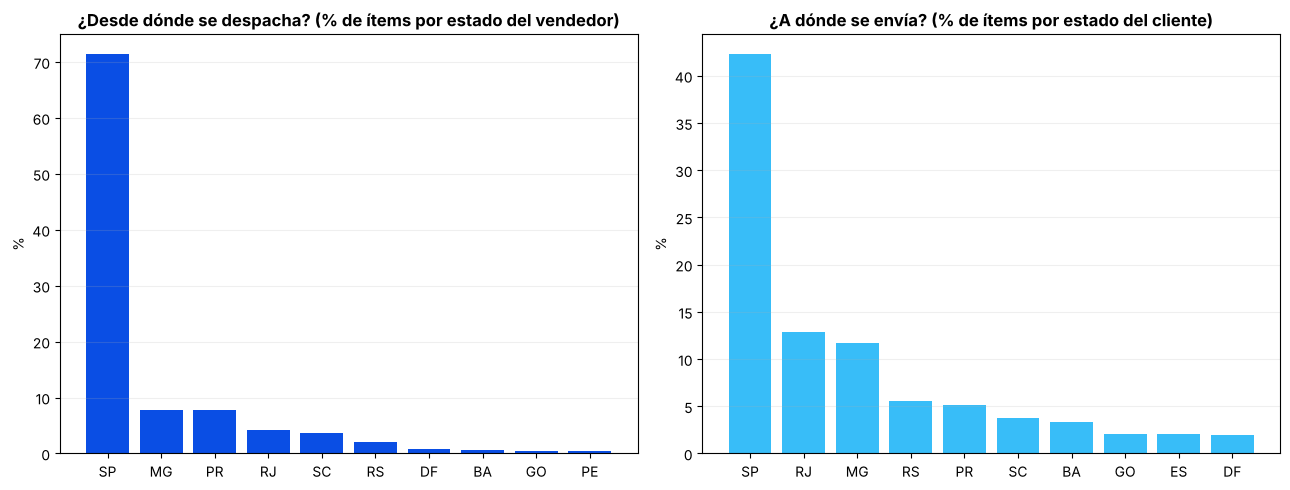

El 71% de los ítems sale del estado de São Paulo, pero solo el 42% de los clientes está ahí.


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
vend = df.groupby("seller_state").size().sort_values(ascending=False).head(10)
clie = df.groupby("customer_state").size().sort_values(ascending=False).head(10)
axes[0].bar(vend.index, vend.values / len(df) * 100, color="#0A4EE4")
axes[0].set_title("¿Desde dónde se despacha? (% de ítems por estado del vendedor)", fontweight="bold")
axes[1].bar(clie.index, clie.values / len(df) * 100, color="#38BDF8")
axes[1].set_title("¿A dónde se envía? (% de ítems por estado del cliente)", fontweight="bold")
for ax in axes: ax.set_ylabel("%"); ax.grid(axis="y", alpha=.2)
plt.tight_layout(); plt.show()
print(f"El {(df.seller_state=='SP').mean():.0%} de los ítems sale del estado de São Paulo, "
      f"pero solo el {(df.customer_state=='SP').mean():.0%} de los clientes está ahí.")

### Paso 3. ¿Cuánto cuesta enviar un ítem? Regresión con los fletes reales

Para evaluar rutas que hoy **no existen** (por ejemplo, desde un CD en Recife) necesitamos una función de costo. La estimamos con **mínimos cuadrados** sobre los fletes realmente pagados:

$$\text{flete} = \beta_0 + \beta_1\,\tfrac{\text{km}}{1000} + \beta_2\,\text{kg} + \beta_3\,\tfrac{\text{km}}{1000}\cdot\text{kg}$$

Con el mismo método estimamos los días de entrega en función de la distancia.

In [6]:
X = np.column_stack([np.ones(len(df)), df.dist_km/1000, df.kg, df.dist_km/1000 * df.kg])
y = df.freight_value.values
beta, *_ = np.linalg.lstsq(X, y, rcond=None)
resid = y - X @ beta
r2 = 1 - (resid**2).sum() / ((y - y.mean())**2).sum()
sigma2 = (resid**2).sum() / (len(y) - X.shape[1])
cov_beta = sigma2 * np.linalg.inv(X.T @ X)          # para el Monte Carlo

m = df.dias_entrega.notna()
Xd = np.column_stack([np.ones(m.sum()), df.dist_km[m]/1000])
beta_dias, *_ = np.linalg.lstsq(Xd, df.dias_entrega[m].values, rcond=None)

print(pd.DataFrame({"coeficiente": beta, "error estándar": np.sqrt(np.diag(cov_beta))},
                   index=["β0 fijo por ítem (R$)", "β1 por 1000 km (R$)", "β2 por kg (R$)", "β3 por 1000 km·kg (R$)"]))
print(f"\nR² = {r2:.2f}  (n = {len(y):,} ítems)")
print(f"Días de entrega ≈ {beta_dias[0]:.1f} + {beta_dias[1]:.1f} × (km/1000)")

                        coeficiente  error estándar
β0 fijo por ítem (R$)          9.84            0.05
β1 por 1000 km (R$)            7.92            0.06
β2 por kg (R$)                 1.82            0.01
β3 por 1000 km·kg (R$)         1.33            0.01

R² = 0.55  (n = 109,640 ítems)
Días de entrega ≈ 8.2 + 6.3 × (km/1000)


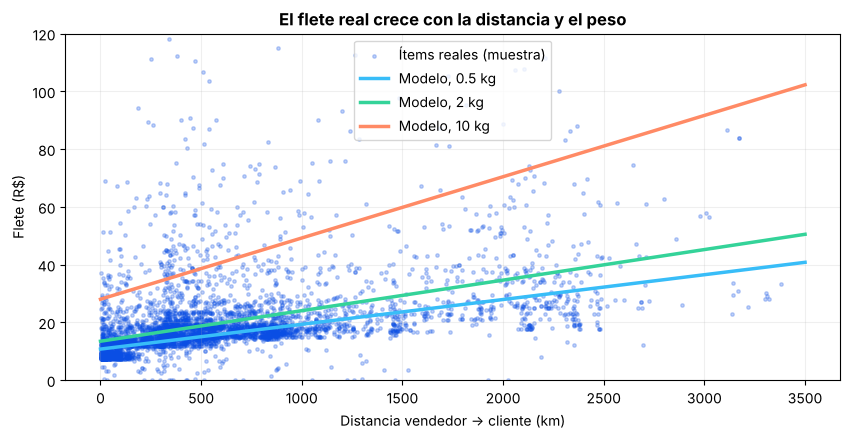

In [7]:
muestra = df.sample(5000, random_state=123)
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.scatter(muestra.dist_km, muestra.freight_value, s=6, alpha=.25, color="#0A4EE4", label="Ítems reales (muestra)")
km = np.linspace(0, 3500, 50)
for kg, col in [(0.5, "#38BDF8"), (2, "#34D399"), (10, "#FF8A65")]:
    ax.plot(km, beta[0] + beta[1]*km/1000 + beta[2]*kg + beta[3]*km/1000*kg, lw=2.5, color=col, label=f"Modelo, {kg} kg")
ax.set_ylim(0, 120); ax.set_xlabel("Distancia vendedor → cliente (km)"); ax.set_ylabel("Flete (R$)")
ax.set_title("El flete real crece con la distancia y el peso", fontweight="bold"); ax.legend(); ax.grid(alpha=.2)
plt.show()

## 4. Situación actual (12 meses: septiembre 2017 a agosto 2018)

Tomamos los últimos 12 meses completos del dataset para expresar todo en **valores anuales**.

In [8]:
anio = df[(df.compra >= "2017-09-01") & (df.compra < "2018-09-01")].copy()
flete_real = anio.freight_value.sum()
flete_modelo_actual = (beta[0]*len(anio) + beta[1]*(anio.dist_km/1000).sum()
                       + beta[2]*anio.kg.sum() + beta[3]*(anio.dist_km/1000*anio.kg).sum())
dist_actual = anio.dist_km.mean()
dias_actual = beta_dias[0] + beta_dias[1]*dist_actual/1000

print(f"Ítems enviados en 12 meses:         {len(anio):,}")
print(f"Flete realmente pagado:             R$ {flete_real:,.0f}")
print(f"Flete según el modelo de regresión: R$ {flete_modelo_actual:,.0f}  (para comparar con el mismo criterio)")
print(f"Distancia promedio por envío:       {dist_actual:,.0f} km")
print(f"Días de entrega reales (promedio):  {anio.dias_entrega.mean():.1f}")

por_estado = anio.groupby("customer_state").agg(items=("order_id", "size"), flete_prom=("freight_value", "mean"),
                                               km_prom=("dist_km", "mean"), dias_prom=("dias_entrega", "mean"))
por_estado.sort_values("flete_prom", ascending=False).head(8)

Ítems enviados en 12 meses:         84,521
Flete realmente pagado:             R$ 1,708,324
Flete según el modelo de regresión: R$ 1,669,395  (para comparar con el mismo criterio)
Distancia promedio por envío:       587 km
Días de entrega reales (promedio):  12.1


,items,flete_prom,km_prom,dias_prom
customer_state,,,,
RR,32,48.91,3237.66,26.72
PB,429,45.63,2091.04,19.63
AC,53,45.19,2677.92,20.04
RO,179,45.04,2222.56,19.12
PI,389,40.67,1937.31,19.08
MA,588,40.64,2076.40,21.84
TO,232,39.60,1475.27,17.54
AL,306,38.01,1814.03,23.48


## 5. Formulación del problema de optimización (p-mediana)

**Conjuntos**
- $I$: regiones de demanda = prefijos de 3 dígitos del código postal (CEP) de los clientes.
- $J$: ubicaciones candidatas para CD = las **27 capitales de estado** (coordenadas tomadas de los mismos datos).

**Parámetros (todos calculados con datos reales)**
- $n_i$: ítems enviados a la región $i$ en 12 meses; $w_i$: kg enviados a la región $i$.
- $d_{ij}$: distancia del CD $j$ a la región $i$ (km).
- $c_{ij} = \beta_0 n_i + \beta_1 \tfrac{d_{ij}}{1000} n_i + \beta_2 w_i + \beta_3 \tfrac{d_{ij}}{1000} w_i$: flete anual estimado si la región $i$ se atiende desde $j$.
- $p$: número de CD a abrir (escenario de decisión).

**Variables de decisión**
- $y_j \in \{0,1\}$: 1 si se abre un CD en la capital $j$.
- $x_{ij} \in [0,1]$: fracción de la demanda de la región $i$ atendida desde $j$.

**Función objetivo:** $\min \sum_{i}\sum_{j} c_{ij}\,x_{ij}$  (flete anual de última milla)

**Restricciones**
1. Toda la demanda se atiende: $\sum_j x_{ij} = 1 \quad \forall i$
2. Solo se atiende desde CD abiertos: $x_{ij} \le y_j \quad \forall i,j$
3. Se abren exactamente $p$ CD: $\sum_j y_j = p$

**Supuestos:** los CD no tienen límite de capacidad; el costo de llevar mercadería del vendedor al CD (*inbound*) y de operar el CD **no se incluye** porque Olist no lo publica. Por eso interpretamos el ahorro como **el monto máximo que Olist podría gastar en esos conceptos** para que el CD siga conviniendo (punto de equilibrio).

In [9]:
capitales = {"AC": "rio branco", "AL": "maceio", "AP": "macapa", "AM": "manaus", "BA": "salvador",
             "CE": "fortaleza", "DF": "brasilia", "ES": "vitoria", "GO": "goiania", "MA": "sao luis",
             "MT": "cuiaba", "MS": "campo grande", "MG": "belo horizonte", "PA": "belem", "PB": "joao pessoa",
             "PR": "curitiba", "PE": "recife", "PI": "teresina", "RJ": "rio de janeiro", "RN": "natal",
             "RS": "porto alegre", "RO": "porto velho", "RR": "boa vista", "SC": "florianopolis",
             "SP": "sao paulo", "SE": "aracaju", "TO": "palmas"}
cand = pd.DataFrame([{"cd": f"{ciudad.title()} ({uf})",
                      "lat": df.loc[(df.customer_state == uf) & (df.customer_city == ciudad), "c_lat"].mean(),
                      "lng": df.loc[(df.customer_state == uf) & (df.customer_city == ciudad), "c_lng"].mean()}
                     for uf, ciudad in capitales.items()])

anio["region"] = anio.customer_zip_code_prefix.astype(str).str.zfill(5).str[:3]
dem = anio.groupby("region").agg(n=("order_id", "size"), kg=("kg", "sum"),
                                 lat=("c_lat", "mean"), lng=("c_lng", "mean"),
                                 estado=("customer_state", lambda s: s.mode()[0])).reset_index()

D = haversine_km(dem.lat.values[:, None], dem.lng.values[:, None], cand.lat.values[None, :], cand.lng.values[None, :])
n, w = dem.n.values[:, None], dem.kg.values[:, None]
def matriz_costos(b):
    return b[0]*n + b[1]*D/1000*n + b[2]*w + b[3]*D/1000*w
COSTO = matriz_costos(beta)

print(f"Regiones de demanda: {len(dem)} | Capitales candidatas: {len(cand)} | Variables x: {COSTO.size:,}")

Regiones de demanda: 848 | Capitales candidatas: 27 | Variables x: 22,896


In [10]:
def resolver_pmediana(p, costo=COSTO, limite_seg=120):
    I, J = range(costo.shape[0]), range(costo.shape[1])
    modelo = pulp.LpProblem("p_mediana_Olist", pulp.LpMinimize)
    y = pulp.LpVariable.dicts("abrir", J, cat="Binary")
    x = pulp.LpVariable.dicts("asignar", [(i, j) for i in I for j in J], lowBound=0, upBound=1)

    modelo += pulp.lpSum(costo[i, j] * x[i, j] for i in I for j in J)
    for i in I:
        modelo += pulp.lpSum(x[i, j] for j in J) == 1
        for j in J:
            modelo += x[i, j] <= y[j]
    modelo += pulp.lpSum(y[j] for j in J) == p

    t0 = time.time()
    modelo.solve(pulp.PULP_CBC_CMD(msg=False, timeLimit=limite_seg))
    abiertos = [j for j in J if y[j].value() > 0.5]
    asign = np.array([max(J, key=lambda j: x[i, j].value()) for i in I])
    return {"p": p, "abiertos": abiertos, "asignacion": asign, "flete": pulp.value(modelo.objective),
            "estado": pulp.LpStatus[modelo.status], "seg": time.time() - t0}

sol3 = resolver_pmediana(3)
print("Estado:", sol3["estado"], f"| tiempo: {sol3['seg']:.1f} s")
print("CD elegidos:", ", ".join(cand.cd[j] for j in sol3["abiertos"]))
print(f"Flete anual estimado: R$ {sol3['flete']:,.0f}  vs. actual R$ {flete_modelo_actual:,.0f}"
      f"  → ahorro R$ {flete_modelo_actual - sol3['flete']:,.0f} ({1 - sol3['flete']/flete_modelo_actual:.1%})")

Estado: Optimal | tiempo: 4.7 s
CD elegidos: Rio De Janeiro (RJ), Sao Paulo (SP), Aracaju (SE)
Flete anual estimado: R$ 1,427,528  vs. actual R$ 1,669,395  → ahorro R$ 241,867 (14.5%)


## 6. Resultados y análisis de sensibilidad: ¿cuántos CD?

Resolvemos el modelo para $p = 1, \dots, 8$ y medimos el ahorro, la distancia promedio y los días de entrega estimados.

In [11]:
filas, soluciones = [], {}
for p in range(1, 9):
    s = resolver_pmediana(p)
    soluciones[p] = s
    km_prom = (D[np.arange(len(dem)), s["asignacion"]] * dem.n).sum() / dem.n.sum()
    filas.append({"CD (p)": p,
                  "ubicaciones": ", ".join(cand.cd[j] for j in s["abiertos"]),
                  "flete anual (R$)": s["flete"],
                  "ahorro anual (R$)": flete_modelo_actual - s["flete"],
                  "ahorro %": 1 - s["flete"] / flete_modelo_actual,
                  "km promedio": km_prom,
                  "días estimados": beta_dias[0] + beta_dias[1] * km_prom / 1000,
                  "estado": s["estado"]})
sens = pd.DataFrame(filas)
sens["ahorro marginal (R$)"] = sens["ahorro anual (R$)"].diff().fillna(sens["ahorro anual (R$)"])
sens.style.format({"flete anual (R$)": "{:,.0f}", "ahorro anual (R$)": "{:,.0f}", "ahorro %": "{:.1%}",
                   "km promedio": "{:,.0f}", "días estimados": "{:.1f}", "ahorro marginal (R$)": "{:,.0f}"})

,CD (p),ubicaciones,flete anual (R$),ahorro anual (R$),ahorro %,km promedio,días estimados,estado,ahorro marginal (R$)
0,1,Sao Paulo (SP),"1,600,179","69,216",4.1%,506,11.4,Optimal,"69,216"
1,2,"Sao Paulo (SP), Aracaju (SE)","1,483,671","185,723",11.1%,377,10.6,Optimal,"116,508"
2,3,"Rio De Janeiro (RJ), Sao Paulo (SP), Aracaju (SE)","1,427,528","241,867",14.5%,315,10.2,Optimal,"56,144"
3,4,"Rio De Janeiro (RJ), Porto Alegre (RS), Sao Paulo (SP), Aracaju (SE)","1,385,268","284,127",17.0%,268,9.9,Optimal,"42,260"
4,5,"Goiania (GO), Rio De Janeiro (RJ), Porto Alegre (RS), Sao Paulo (SP), Aracaju (SE)","1,343,947","325,448",19.5%,222,9.6,Optimal,"41,321"
5,6,"Goiania (GO), Belo Horizonte (MG), Rio De Janeiro (RJ), Porto Alegre (RS), Sao Paulo (SP), Aracaju (SE)","1,322,676","346,719",20.8%,198,9.5,Optimal,"21,271"
6,7,"Goiania (GO), Sao Luis (MA), Belo Horizonte (MG), Rio De Janeiro (RJ), Porto Alegre (RS), Sao Paulo (SP), Aracaju (SE)","1,302,969","366,425",21.9%,176,9.3,Optimal,"19,706"
7,8,"Goiania (GO), Sao Luis (MA), Belo Horizonte (MG), Curitiba (PR), Rio De Janeiro (RJ), Porto Alegre (RS), Sao Paulo (SP), Aracaju (SE)","1,286,282","383,113",22.9%,157,9.2,Optimal,"16,687"


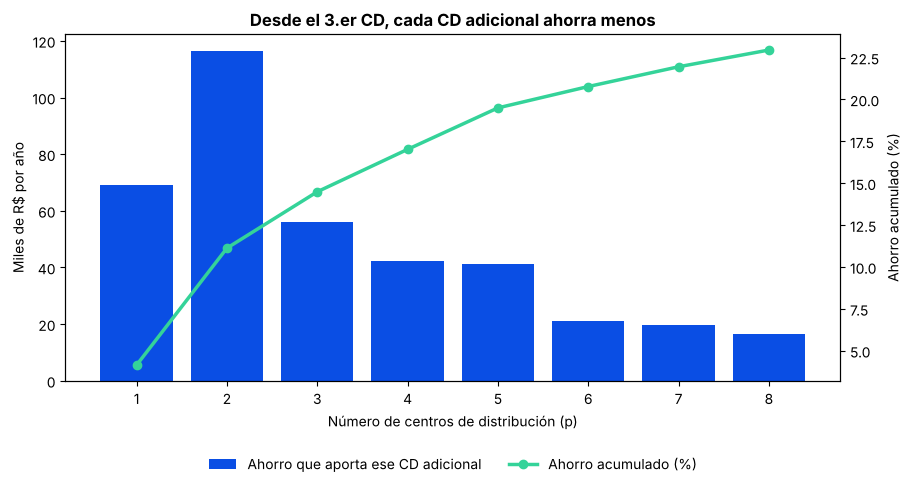

In [12]:
fig, ax1 = plt.subplots(figsize=(10, 4.5))
ax1.bar(sens["CD (p)"], sens["ahorro marginal (R$)"] / 1000, color="#0A4EE4", label="Ahorro que aporta ese CD adicional")
ax1.set_xlabel("Número de centros de distribución (p)"); ax1.set_ylabel("Miles de R$ por año")
ax2 = ax1.twinx()
ax2.plot(sens["CD (p)"], sens["ahorro %"] * 100, "o-", color="#34D399", lw=2.5, label="Ahorro acumulado (%)")
ax2.set_ylabel("Ahorro acumulado (%)")
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper center", bbox_to_anchor=(.5, -.18), ncol=2, frameon=False)
ax1.set_title("Desde el 3.er CD, cada CD adicional ahorra menos", fontweight="bold")
plt.show()

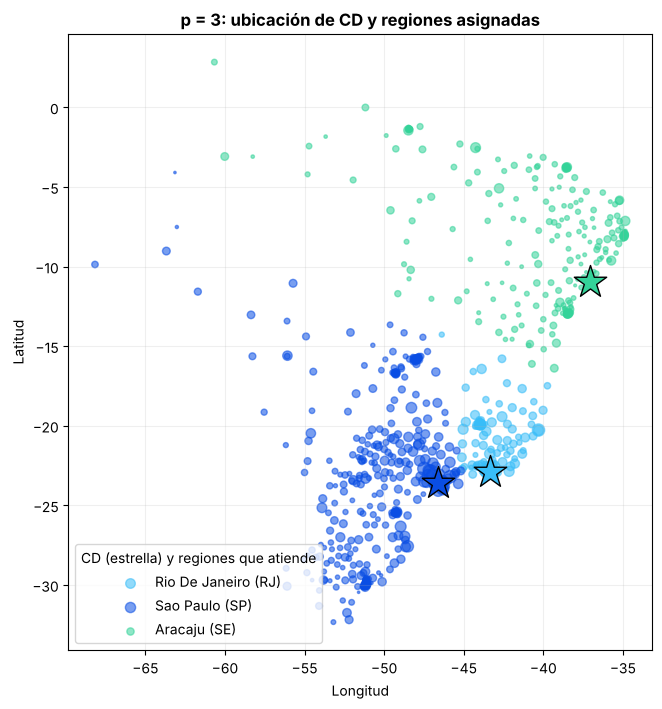

In [13]:
def dibujar(sol, titulo):
    colores = ["#38BDF8", "#0A4EE4", "#34D399", "#FF8A65", "#FFC94D", "#A78BFA", "#6FA0FF", "#F472B6"]
    fig, ax = plt.subplots(figsize=(8, 8))
    for k, j in enumerate(sol["abiertos"]):
        r = dem[sol["asignacion"] == j]
        ax.scatter(r.lng, r.lat, s=np.sqrt(r.n) * 3, color=colores[k % 10], alpha=.55, label=cand.cd[j])
        ax.scatter(cand.lng[j], cand.lat[j], marker="*", s=600, color=colores[k % 10], edgecolor="black", zorder=5)
    ax.set_title(titulo, fontweight="bold"); ax.set_xlabel("Longitud"); ax.set_ylabel("Latitud")
    ax.set_aspect("equal"); ax.grid(alpha=.2); ax.legend(loc="lower left", title="CD (estrella) y regiones que atiende")
    plt.show()

dibujar(soluciones[3], "p = 3: ubicación de CD y regiones asignadas")

### Regla de decisión (punto de equilibrio)

Olist no publica cuánto cuesta operar un CD ni el transporte desde los vendedores. Por eso el modelo entrega una **regla de decisión** en lugar de un número único: **abrir el CD número *p* solo si su costo anual (alquiler, personal e *inbound*) es menor que el ahorro marginal que aporta** (última columna de la tabla).

## 7. ¿Qué tan segura es la recomendación? Simulación Monte Carlo

Dos fuentes de incertidumbre, ambas medidas con los datos:
1. **Demanda:** el volumen y la mezcla de regiones cambian mes a mes. Armamos "años simulados" eligiendo al azar 12 meses (con reemplazo) entre los 12 meses observados (*bootstrap*).
2. **Costo de flete:** los coeficientes de la regresión tienen error estadístico; los sorteamos de su distribución estimada.

En cada uno de **1,000 años simulados** medimos: (a) el ahorro de la red elegida (São Paulo, Rio de Janeiro y Aracaju) y (b) si esa terna **sigue siendo la mejor** entre las 2,925 combinaciones posibles de 3 capitales.

Ahorro anual con 3 CD: mediana R$ 241,612 | intervalo 90 %: R$ 224,966 a R$ 259,059
Ahorro en % del flete: mediana 14.5%
La terna São Paulo, Rio de Janeiro y Aracaju es la óptima en el 100% de los años simulados


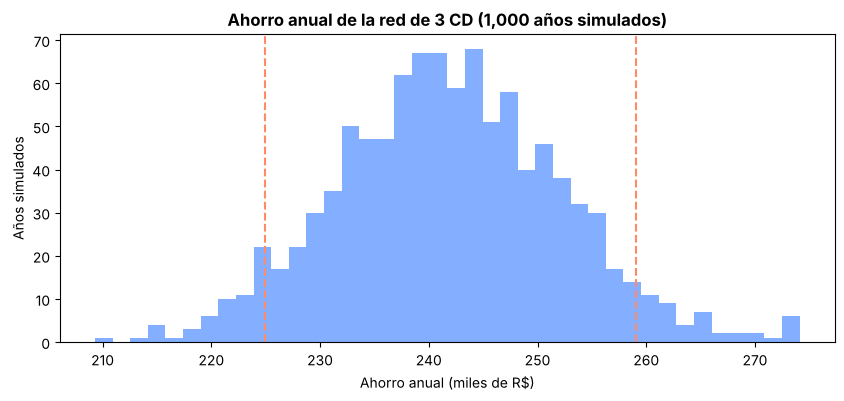

In [14]:
from itertools import combinations
N_SIM = 1000
rng = np.random.default_rng(123)

anio["mes"] = anio.compra.dt.to_period("M")
meses = anio.mes.unique()
reg_idx = {r: k for k, r in enumerate(dem.region)}
anio["ri"] = anio.region.map(reg_idx)
n_mes  = anio.pivot_table(index="mes", columns="ri", values="kg", aggfunc="size", fill_value=0).reindex(columns=range(len(dem)), fill_value=0)
kg_mes = anio.pivot_table(index="mes", columns="ri", values="kg", aggfunc="sum", fill_value=0).reindex(columns=range(len(dem)), fill_value=0)
km_mes = anio.assign(km=anio.dist_km/1000, kmkg=anio.dist_km/1000*anio.kg).groupby("mes")[["km", "kmkg"]].sum()

combos = np.array(list(combinations(range(len(cand)), 3)))
elegida = tuple(sorted(soluciones[3]["abiertos"]))
ahorros, misma = [], 0
for _ in range(N_SIM):
    m = rng.choice(len(meses), size=12, replace=True)
    nn, ww = n_mes.values[m].sum(0)[:, None], kg_mes.values[m].sum(0)[:, None]
    b = rng.multivariate_normal(beta, cov_beta)
    C = b[0]*nn + b[1]*D/1000*nn + b[2]*ww + b[3]*D/1000*ww
    actual = b[0]*nn.sum() + b[1]*km_mes.km.values[m].sum() + b[2]*ww.sum() + b[3]*km_mes.kmkg.values[m].sum()
    costos_combo = C[:, combos].min(axis=2).sum(axis=0)
    mejor = tuple(combos[costos_combo.argmin()])
    misma += (mejor == elegida)
    ahorros.append(actual - C[:, list(elegida)].min(axis=1).sum())
ahorros = np.array(ahorros)

p5, p50, p95 = np.percentile(ahorros, [5, 50, 95])
print(f"Ahorro anual con 3 CD: mediana R$ {p50:,.0f} | intervalo 90 %: R$ {p5:,.0f} a R$ {p95:,.0f}")
print(f"Ahorro en % del flete: mediana {np.median(ahorros)/flete_modelo_actual:.1%}")
print(f"La terna São Paulo, Rio de Janeiro y Aracaju es la óptima en el {misma/N_SIM:.0%} de los años simulados")

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(ahorros / 1000, bins=40, color="#6FA0FF", alpha=.85)
for v in (p5, p95): ax.axvline(v / 1000, color="#FF8A65", ls="--")
ax.set_xlabel("Ahorro anual (miles de R$)"); ax.set_ylabel("Años simulados")
ax.set_title("Ahorro anual de la red de 3 CD (1,000 años simulados)", fontweight="bold")
plt.show()

## 8. Conclusiones, limitaciones y recomendaciones

Las cifras exactas están en las tablas de arriba; aquí resumimos la lectura.

**Resultados**
- El 71 % de los ítems sale del estado de São Paulo, pero solo el 42 % de los clientes vive ahí. Hoy un envío recorre en promedio 587 km y el flete anual es de R$ 1.71 millones.
- Con **3 CD en São Paulo, Rio de Janeiro y Aracaju**, el flete de última milla estimado baja **14.5 % (≈R$ 242 mil por año)** y la distancia promedio baja de 587 a 315 km.
- El CD más valioso después de São Paulo es **Aracaju** (aporta R$ 117 mil por año), porque acerca la mercadería al Nordeste, donde el flete promedio supera los R$ 40 por ítem.
- Desde el 3.er CD los ahorros marginales caen: el 4.º aporta R$ 42 mil y el 8.º solo R$ 17 mil.
- En 1,000 años simulados el ahorro de los 3 CD queda entre R$ 225 mil y R$ 259 mil (90 % de los casos), y esa misma terna es la óptima en el 100 % de las simulaciones.

**Limitaciones**
- El flete se estima con una regresión lineal (R² ≈ 0.55): explica algo más de la mitad de la variación del flete.
- Distancias en línea recta, sin red vial.
- No incluimos el costo de *inbound* ni de operación del CD porque no son públicos; lo resolvemos con la regla de punto de equilibrio.
- Los CD no tienen capacidad máxima y solo consideramos capitales como candidatas.
- Los datos son una muestra de pedidos de 2016 a 2018 publicada por Olist; puede no reflejar el volumen actual de la empresa.

**Recomendaciones a Olist**
1. Evaluar una red de 3 CD (São Paulo, Rio de Janeiro y Aracaju), empezando por Aracaju para el Nordeste.
2. Abrir cada CD solo si su costo anual de operación e *inbound* es menor que su ahorro marginal (p. ej., menos de R$ 117 mil por año para Aracaju).
3. Para afinar: sumar el costo real de *inbound* y de operación, y usar distancias por carretera.

**Aprendizajes del equipo**
- Un modelo de optimización necesita parámetros con fundamento: los estimamos con datos reales en lugar de suponerlos.
- Cuando falta un dato (costo del CD), se puede convertir la respuesta en una regla de decisión.
- Combinar regresión (predecir), optimización (decidir) y Monte Carlo (medir el riesgo) da una recomendación más sólida.